# ATHENS — RGB × RAVE (Windows / CUDA or CPU prototype)
Piano → R, drums → G, bass → B. No training. Use your own aligned WAV stems (same start time). Default: render a neural effect once per stem, then RGB controls wet/dry mixing. Optional latent offset experiment below. Model: Tangible Music Lab, Freesound Loop 10K Raspberry Pi export (44.1 kHz, 2048 sample blocks). [Model card](https://huggingface.co/Tangible-Music-Lab/RAVE_models) · [RAVE](https://github.com/acids-ircam/RAVE).

**Model security:** use only trusted TorchScript files; Hugging Face flags these exports for review. TorchScript is executable, so verify provenance and use an isolated, disposable runtime with no secrets or mounted personal drives. The notebook does not download or load weights until you explicitly set the trust switch. No copyrighted audio included. Use audio you have permission to process/share. This is an experimental prototype, not a guaranteed instrument substitution.

In [1]:
# Step 1: check the active notebook environment and GPU.
import sys, torch
from pathlib import Path
print('Python:', sys.executable)
print('Working directory:', Path.cwd())
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only')


Python: d:\ATHENS_RAVE\.venv\Scripts\python.exe
Working directory: d:\ATHENS_RAVE
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


In [7]:
import os, time, math
from pathlib import Path
import numpy as np
import soundfile as sf
import torch
from scipy.signal import resample_poly
from IPython.display import display, Audio
from huggingface_hub import hf_hub_download
SR = 44100
BLOCK = 2048
START_SECONDS = 10
MAX_SECONDS = 20
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'  # change to 'cpu' if export fails on CUDA
print('RAVE device:', DEVICE)
torch.set_num_threads(min(4, os.cpu_count() or 1))
REPO = 'Tangible-Music-Lab/RAVE_models'
FILE = 'freesoundloop10k_raspi_b2048_r44100_z16.ts'
TRUST_MODEL = True # set True only after reviewing the source and using an isolated runtime
LOCAL_MODEL = '' # optionally supply a trusted local .ts file
assert TRUST_MODEL, 'Use only a verified trusted model or an isolated disposable runtime; then set TRUST_MODEL=True.'
MODEL = Path(LOCAL_MODEL or hf_hub_download(repo_id=REPO, filename=FILE, revision='3bf275f'))
print(MODEL, MODEL.stat().st_size / 1e6, 'MB')
model = torch.jit.load(str(MODEL), map_location=DEVICE).eval()
print('Exported methods:', model._c._method_names())
assert hasattr(model, 'encode') and hasattr(model, 'decode'), 'Choose an encoder/decoder export.'
del model

RAVE device: cuda
C:\Users\Flynn\.cache\huggingface\hub\models--Tangible-Music-Lab--RAVE_models\snapshots\3bf275ff6e223ddf9e82aacc5e9933f4af401fe8\freesoundloop10k_raspi_b2048_r44100_z16.ts 23.628568 MB
Exported methods: ['forward', 'decode', 'encode', 'encode_dist', 'get_attributes', 'get_learn_source', 'get_learn_target', 'get_methods', 'get_reset_source', 'get_reset_target', 'prior', 'set_learn_source', 'set_learn_target', 'set_reset_source', 'set_reset_target', 'set_stereo_mode', 'update_adain', 'post_process_latent', 'pre_process_latent']


## 1. Upload audio
In Colab, upload exactly three aligned files named `piano.wav`, `drums.wav`, `bass.wav` (or edit the paths). Locally put them next to the notebook. For the first test only 12 seconds are used. No per-track normalization of originals; mono downmix at 44.1 kHz.

In [8]:
# Optional Colab upload: uncomment these 2 lines
# from google.colab import files
# files.upload()
PATHS = {'piano':'piano.wav', 'drums':'drums.wav', 'bass':'bass.wav'}

def read_stem(path):
    with sf.SoundFile(path) as f:
        sr = f.samplerate

        # Skip the first 10 seconds
        f.seek(int(START_SECONDS * sr))

        # Read the next 20 seconds
        x = f.read(
            int(MAX_SECONDS * sr),
            dtype='float32',
            always_2d=True
        ).mean(axis=1)

    if sr != SR:
        g = math.gcd(sr, SR)
        x = resample_poly(x, SR//g, sr//g)

    return x.astype(np.float32)

dry = {k:read_stem(p) for k,p in PATHS.items()}
N = min(map(len, dry.values()))
assert N > 0, 'Empty stem'
dry = {k:v[:N] for k,v in dry.items()}
peak = max(np.max(np.abs(v)) for v in dry.values())
if peak > 0.95:
    dry = {k:v*(0.95/peak) for k,v in dry.items()}
print('Duration:', N/SR, 's')
for k,v in dry.items():
    print(k, 'RMS:', np.sqrt(np.mean(v*v)))

Duration: 20.0 s
piano RMS: 0.00237972
drums RMS: 0.042963017
bass RMS: 0.009224253


## 2. Run a neural audio effect
A fresh streaming model for each render avoids state leakage. Model input: [batch, channels, samples]. One 2048-sample block at a time. `offset=0` is the reconstruction baseline, nonzero adds a value to one latent coordinate. The coordinate is not assumed to have a particular semantic meaning. An extra 0.5 s tail allows manual latency compensation. If the model fails on a block, inspect the printed methods and error rather than silently skipping it.

In [9]:
def render_effect(x, dim=0, offset=0.0):
    torch.manual_seed(42)
    m = torch.jit.load(str(MODEL), map_location=DEVICE).eval()
    target = len(x) + int(0.5*SR)
    padded_len = math.ceil(target/BLOCK)*BLOCK
    padded = np.pad(x, (0,padded_len-len(x)))
    out = []
    with torch.inference_mode():
        for i in range(0,padded_len,BLOCK):
            t = torch.from_numpy(padded[i:i+BLOCK].copy()).reshape(1,1,BLOCK).to(DEVICE)
            z = m.encode(t)
            if i == 0: print('latent shape:', tuple(z.shape))
            if z.ndim != 3 or not 0 <= dim < z.shape[1]:
                raise ValueError(f'Unexpected latent shape or dim: {z.shape}, {dim}')
            z = z.clone()
            z[:,dim,:] += offset
            y = m.decode(z)
            if y.ndim != 3 or y.shape[0] != 1 or y.shape[-1] != BLOCK:
                raise ValueError(f'Unexpected output shape: {y.shape}')
            out.append(y[0].mean(dim=0).cpu().numpy())
    result = np.concatenate(out).astype(np.float32)
    if not np.isfinite(result).all(): raise ValueError('Model output contains NaN or Inf')
    return result

def align_wet(w, x, delay_samples=0):
    # Positive delay advances the model output to compensate for model latency.
    if delay_samples < 0:
        w = np.pad(w, (-delay_samples,0))
    else:
        w = w[delay_samples:]
    w = np.pad(w,(0,max(0,len(x)-len(w))))[:len(x)]
    rms = lambda a: float(np.sqrt(np.mean(a*a)))
    # Match RMS to the dry stem, cap the gain to avoid boosting weak/noisy output.
    return w * min(4.0, rms(x)/(rms(w)+1e-8))

def safe_audio(x):
    return Audio(x,rate=SR,normalize=False)

def peak_safe(x):
    return x*min(1.0,0.95/(float(np.max(np.abs(x)))+1e-8))

# First, test only one 3-second input; leave other cells until this works.
test = dry['drums']
t0 = time.perf_counter()
raw_test = render_effect(test, dim=0, offset=0.0)
print('Inference time:', round(time.perf_counter()-t0,2),'seconds')
DELAY_TEST = 0 # adjust after listening or viewing waveform; not assumed to be zero
wtest = align_wet(raw_test,test,DELAY_TEST)
print('Dry'); display(safe_audio(peak_safe(test)))
print('Wet reconstruction'); display(safe_audio(peak_safe(wtest)))

latent shape: (1, 16, 1)
Inference time: 3.86 seconds
Dry


Wet reconstruction


## 3. Optional: audition latent coordinate changes
Run this on the same short drum clip, compare with zero offset. Try other dimensions if needed. Large offsets may destroy notes or groove; these are experiments, not mood labels.

In [11]:
DIM = 0

for a in [-1.5, -0.5, 0, 0.5, 1.5]:
    print('Dimension:', DIM, 'Offset:', a)

    wy = align_wet(
        render_effect(test, dim=DIM, offset=a),
        test,
        DELAY_TEST
    )

    display(safe_audio(peak_safe(wy)))

Dimension: 0 Offset: -1.5
latent shape: (1, 16, 1)


Dimension: 0 Offset: -0.5
latent shape: (1, 16, 1)


Dimension: 0 Offset: 0
latent shape: (1, 16, 1)


Dimension: 0 Offset: 0.5
latent shape: (1, 16, 1)


Dimension: 0 Offset: 1.5
latent shape: (1, 16, 1)


latent shape: (1, 16, 1)
Offset: -1.5, Power-weighted centroid: 845.0 Hz
latent shape: (1, 16, 1)
Offset: -0.5, Power-weighted centroid: 1014.6 Hz
latent shape: (1, 16, 1)
Offset: +0.0, Power-weighted centroid: 761.3 Hz
latent shape: (1, 16, 1)
Offset: +0.5, Power-weighted centroid: 1204.2 Hz
latent shape: (1, 16, 1)
Offset: +1.5, Power-weighted centroid: 3352.1 Hz


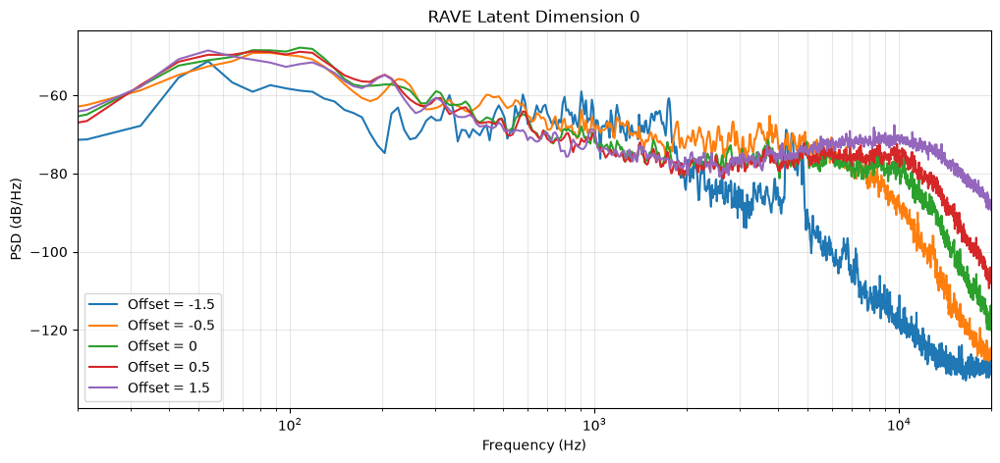

In [13]:
import matplotlib.pyplot as plt
from scipy.signal import welch

DIM = 0
OFFSETS = [-1.5, -0.5, 0, 0.5, 1.5]

plt.figure(figsize=(12, 5))

for a in OFFSETS:
    torch.manual_seed(42)

    y = align_wet(
        render_effect(test, dim=DIM, offset=a),
        test,
        DELAY_TEST
    )

    f, psd = welch(y, fs=SR, nperseg=4096)

    centroid = np.sum(f * psd) / (np.sum(psd) + 1e-20)

    print(f"Offset: {a:+.1f}, "
          f"Power-weighted centroid: {centroid:.1f} Hz")

    plt.semilogx(
        f[1:],
        10 * np.log10(psd[1:] + 1e-20),
        label=f"Offset = {a}"
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB/Hz)")
plt.title(f"RAVE Latent Dimension {DIM}")
plt.xlim(20, 20000)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

In [14]:
from scipy.signal import welch
import matplotlib.pyplot as plt

def spectral_centroid(x):
    f, psd = welch(x, fs=SR, nperseg=4096)
    return np.sum(f * psd) / (np.sum(psd) + 1e-20)

DIMS = [0, 1, 2]
OFFSETS = [-1.5, -0.5, 0, 0.5, 1.5]

results = {}

for instrument in ['piano', 'drums', 'bass']:

    print(f"\nProcessing {instrument}")

    # Only use 5 seconds for faster scanning
    x = dry[instrument][:5 * SR]

    results[instrument] = {}

    for dim in DIMS:

        centroids = []

        for offset in OFFSETS:

            torch.manual_seed(42)

            y = render_effect(
                x,
                dim=dim,
                offset=offset
            )

            c = spectral_centroid(y)
            centroids.append(c)

            print(
                f"{instrument:6s} | "
                f"DIM {dim} | "
                f"Offset {offset:+.1f} | "
                f"{c:.1f} Hz"
            )

        results[instrument][dim] = centroids


Processing piano
latent shape: (1, 16, 1)
piano  | DIM 0 | Offset -1.5 | 627.7 Hz
latent shape: (1, 16, 1)
piano  | DIM 0 | Offset -0.5 | 587.7 Hz
latent shape: (1, 16, 1)
piano  | DIM 0 | Offset +0.0 | 406.0 Hz
latent shape: (1, 16, 1)
piano  | DIM 0 | Offset +0.5 | 378.0 Hz
latent shape: (1, 16, 1)
piano  | DIM 0 | Offset +1.5 | 255.3 Hz
latent shape: (1, 16, 1)
piano  | DIM 1 | Offset -1.5 | 458.7 Hz
latent shape: (1, 16, 1)
piano  | DIM 1 | Offset -0.5 | 483.5 Hz
latent shape: (1, 16, 1)
piano  | DIM 1 | Offset +0.0 | 406.0 Hz
latent shape: (1, 16, 1)
piano  | DIM 1 | Offset +0.5 | 435.7 Hz
latent shape: (1, 16, 1)
piano  | DIM 1 | Offset +1.5 | 898.9 Hz
latent shape: (1, 16, 1)
piano  | DIM 2 | Offset -1.5 | 625.2 Hz
latent shape: (1, 16, 1)
piano  | DIM 2 | Offset -0.5 | 411.0 Hz
latent shape: (1, 16, 1)
piano  | DIM 2 | Offset +0.0 | 406.0 Hz
latent shape: (1, 16, 1)
piano  | DIM 2 | Offset +0.5 | 374.6 Hz
latent shape: (1, 16, 1)
piano  | DIM 2 | Offset +1.5 | 191.5 Hz

Proces

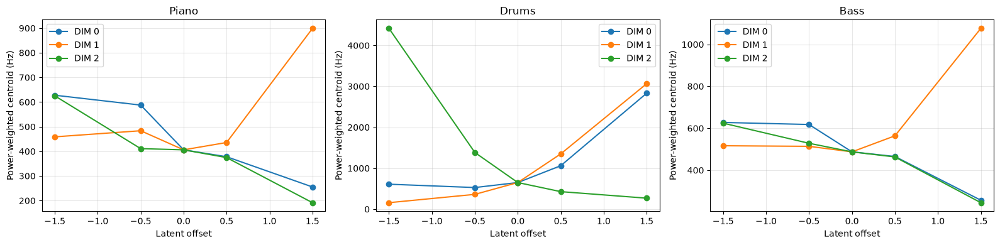

In [15]:
fig, axes = plt.subplots(
    1, 3, figsize=(16, 4)
)

for ax, instrument in zip(
    axes, ['piano', 'drums', 'bass']
):

    for dim in DIMS:

        ax.plot(
            OFFSETS,
            results[instrument][dim],
            marker='o',
            label=f'DIM {dim}'
        )

    ax.set_title(instrument.capitalize())
    ax.set_xlabel('Latent offset')
    ax.set_ylabel('Power-weighted centroid (Hz)')
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

## 4. Pre-render all three stems
Select a small offset and dimension after auditioning; zero is a valid baseline. The RGB picker will control wet/dry strength (not model weights). Set per-stem latency manually after comparing timing. If a stem sounds bad, set its corresponding RGB channel to zero or adjust the configuration. Actual runtime depends on your selected device and model compatibility.

In [ ]:
CONFIG = {
    'piano': (0, -1.5, 0),
    'drums': (1,  1.5, 0),
    'bass':  (1,  1.5, 0)
}
wet = {}
for k,x in dry.items():
    dim,offset,delay = CONFIG[k]
    t0=time.perf_counter()
    wet[k]=align_wet(render_effect(x,dim,offset),x,delay)
    print(k, round(time.perf_counter()-t0,2),'seconds')
    display(safe_audio(peak_safe(wet[k])))

## 5. RGB control and export
`#000000` is the original 3-stem mix; each channel controls one stem's neural wet fraction. `#FF0000` affects piano only, `#00FF00` drums only, `#0000FF` bass only. `#FFFFFF` is fully wet. Keep levels moderate during auditions. A common output gain across dry/wet combinations is used to avoid clipping and preserve comparisons. This is offline AI audio processing with an interactive mixer, not training or live neural inference.

In [ ]:
import re
import ipywidgets as widgets
keys = ['piano','drums','bass']
# This bound is the maximum possible magnitude for any channel mix.
bound = float(np.max(sum(np.maximum(np.abs(dry[k]),np.abs(wet[k])) for k in keys)))
GAIN = min(1.0, 0.95/(bound+1e-8))

def mix_color(color):
    if not re.fullmatch(r'#[0-9a-fA-F]{6}',color): raise ValueError('Use #RRGGBB')
    rgb = [int(color[i:i+2],16)/255 for i in (1,3,5)]
    return (GAIN*sum((1-a)*dry[k]+a*wet[k] for a,k in zip(rgb,keys))).astype(np.float32)

picker=widgets.ColorPicker(description='RGB',value='#804040')
button=widgets.Button(description='Render & save')
out=widgets.Output()
def clicked(_):
    with out:
        out.clear_output(wait=True)
        color=picker.value
        y=mix_color(color)
        path=f'rave_{color[1:]}.wav'
        sf.write(path,y,SR,subtype='PCM_16')
        print('Saved:',path)
        display(safe_audio(y))
button.on_click(clicked)
display(widgets.HBox([picker,button]),out)
print('Original 3-stem mix:')
display(safe_audio(mix_color('#000000')))
# If widgets do not render, run this manually:
# sf.write('rave_FF0000.wav', mix_color('#FF0000'), SR, subtype='PCM_16')

## 6. Optional: direct RGB → latent offset (slower)
This is the professor's direct latent parameter idea: each normalized channel controls offset magnitude instead of wet mix. It reruns inference for every color. At zero, the original stem is bypassed; at nonzero, a wet blend also increases to avoid a discontinuity at zero. Use only after the pre-rendered version works.

In [ ]:
def render_direct(color, max_offset=0.5):
    if not re.fullmatch(r'#[0-9a-fA-F]{6}',color): raise ValueError('Use #RRGGBB')
    rgb = [int(color[i:i+2],16)/255 for i in (1,3,5)]
    output=[]
    for k,a in zip(keys,rgb):
        x=dry[k]
        if a==0: output.append(x); continue
        dim,_,delay=CONFIG[k]
        w=align_wet(render_effect(x,dim,offset=max_offset*a),x,delay)
        output.append((1-a)*x+a*w)
    return peak_safe(sum(output))
# Uncomment to run (slower):
# y=render_direct('#FF8040'); sf.write('direct_RGB.wav',y,SR); display(safe_audio(y))